<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/PADV_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = {
    'Date': [
        '2025-01-05', '2025-01-18',
        '2025-02-05', '2025-02-18',
        '2025-03-05', '2025-03-18',
        '2025-04-05', '2025-04-18',
        '2025-05-05', '2025-05-18',
        '2025-06-05', '2025-06-18',
        '2025-07-05', '2025-07-18',
        '2025-08-05', '2025-08-18',
        '2025-09-05', '2025-09-18',
        '2025-10-05', '2025-10-18',
        '2025-11-05', '2025-11-18',
        '2025-12-05', '2025-12-18'
    ],

    'Region': [
        'North', 'South', 'East', 'West',
        'North', 'South', 'East', 'West',
        'North', 'South', 'East', 'West',
        'North', 'South', 'East', 'West',
        'North', 'South', 'East', 'West',
        'North', 'South', 'East', 'West'
    ],

    'Product': [
        'Laptop', 'Phone', 'Phone', 'Headphones',
        'Laptop', 'Headphones', 'Phone', 'Laptop',
        'Phone', 'Laptop', 'Headphones', 'Phone',
        'Laptop', 'Phone', 'Laptop', 'Headphones',
        'Phone', 'Laptop', 'Headphones', 'Phone',
        'Laptop', 'Phone', 'Laptop', 'Headphones'
    ],

    'Sales': [
        50000, 30000, 35000, 12000,
        55000, 15000, 40000, 48000,
        42000, 60000, 18000, 45000,
        65000, 50000, 70000, 20000,
        55000, 75000, 22000, 60000,
        80000, 65000, 90000, 25000
    ],

    'Profit': [
        8000, 5000, 6000, 2000,
        9000, 2500, 7000, 7500,
        6500, 10000, 3000, 8000,
        11000, 8500, 12000, 3500,
        9000, 13000, 4000, 10000,
        14000, 11000, 16000, 4500
    ],

    'Quantity': [
        10, 15, 17, 20, 11, 25,
        18, 10, 20, 12, 30, 19,
        13, 22, 14, 28, 25, 15,
        32, 27, 16, 30, 18, 35
    ]
}


In [3]:
df = pd.DataFrame(data)

In [4]:
print("RETAIL SALES DATASET")
print(df.head(10))

print("\nDataset Information:")
print(df.info())

RETAIL SALES DATASET
         Date Region     Product  Sales  Profit  Quantity
0  2025-01-05  North      Laptop  50000    8000        10
1  2025-01-18  South       Phone  30000    5000        15
2  2025-02-05   East       Phone  35000    6000        17
3  2025-02-18   West  Headphones  12000    2000        20
4  2025-03-05  North      Laptop  55000    9000        11
5  2025-03-18  South  Headphones  15000    2500        25
6  2025-04-05   East       Phone  40000    7000        18
7  2025-04-18   West      Laptop  48000    7500        10
8  2025-05-05  North       Phone  42000    6500        20
9  2025-05-18  South      Laptop  60000   10000        12

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      24 non-null     object
 1   Region    24 non-null     object
 2   Product   24 non-null     object
 3   Sales     24 non-null 

In [5]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Date        0
Region      0
Product     0
Sales       0
Profit      0
Quantity    0
dtype: int64


In [6]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.strftime('%b')

month_order = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_sales = df.groupby('Month')['Sales'].sum().reindex(month_order)
product_sales = df.groupby('Product')['Sales'].sum()
region_profit = df.groupby('Region')['Profit'].sum()

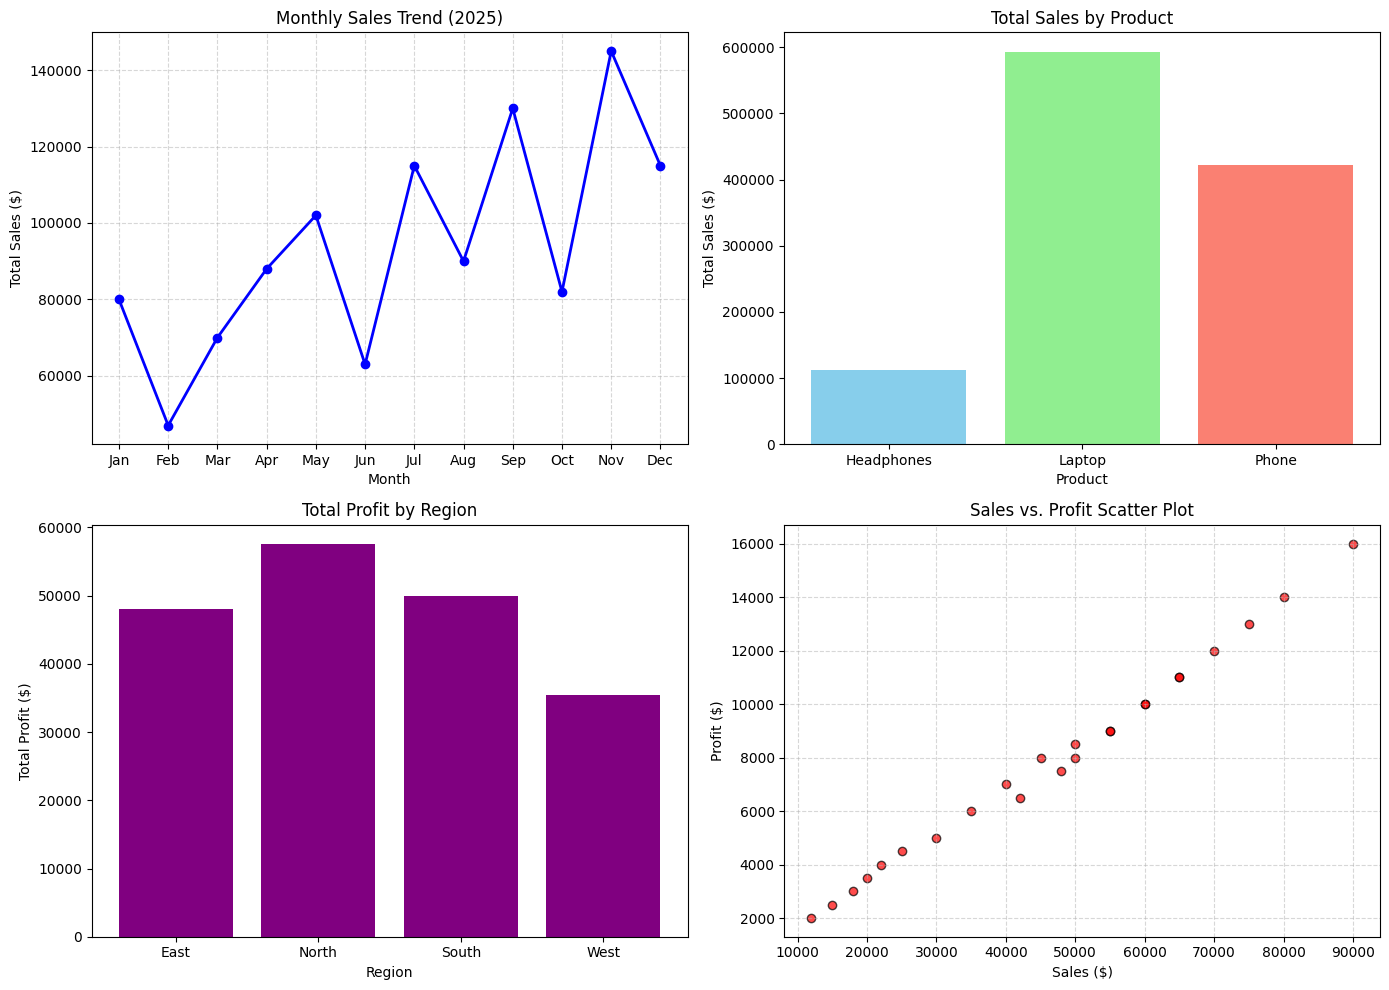

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Monthly Sales Trend (Line Plot)
axes[0, 0].plot(monthly_sales.index, monthly_sales.values, marker='o', color='b', linewidth=2)
axes[0, 0].set_title('Monthly Sales Trend (2025)')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Total Sales ($)')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Sales by Product (Bar Plot)
axes[0, 1].bar(product_sales.index, product_sales.values, color=['skyblue', 'lightgreen', 'salmon'])
axes[0, 1].set_title('Total Sales by Product')
axes[0, 1].set_xlabel('Product')
axes[0, 1].set_ylabel('Total Sales ($)')

# 3. Profit by Region (Bar Plot)
axes[1, 0].bar(region_profit.index, region_profit.values, color='purple')
axes[1, 0].set_title('Total Profit by Region')
axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Total Profit ($)')

# 4. Sales vs Profit Relationship (Scatter Plot)
axes[1, 1].scatter(df['Sales'], df['Profit'], color='red', alpha=0.7, edgecolors='k')
axes[1, 1].set_title('Sales vs. Profit Scatter Plot')
axes[1, 1].set_xlabel('Sales ($)')
axes[1, 1].set_ylabel('Profit ($)')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [9]:
axes[0, 0].plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)
axes[0, 0].set_title('Monthly Sales Trend')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Sales (₹)')
axes[0, 0].grid(True)
axes[0, 0].tick_params(axis='x', rotation=45)

# Visualization 2: Sales by Product
product_sales.plot(
    kind='bar',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Total Sales by Product')
axes[0, 1].set_xlabel('Product')
axes[0, 1].set_ylabel('Sales (₹)')
axes[0, 1].tick_params(axis='x', rotation=0)


In [10]:
region_profit.plot(
    kind='bar',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Total Profit by Region')
axes[1, 0].set_xlabel('Region')
axes[1, 0].set_ylabel('Profit (₹)')
axes[1, 0].tick_params(axis='x', rotation=0)


In [12]:
# Visualization 4: Sales vs Profit
axes[1, 1].scatter(
    df['Sales'],
    df['Profit'],
    s=60
)
axes[1, 1].set_title('Sales vs Profit')
axes[1, 1].set_xlabel('Sales (₹)')
axes[1, 1].set_ylabel('Profit (₹)')
axes[1, 1].grid(True)

plt.suptitle(
    'Retail Sales Analysis: Visual Story',
    fontsize=16
)
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [13]:
print("\n========== BUSINESS INSIGHTS ==========")

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()

best_month = monthly_sales.idxmax()
best_product = product_sales.idxmax()
best_region = region_profit.idxmax()

print("Total Sales: ₹", format(total_sales, ','))
print("Total Profit: ₹", format(total_profit, ','))
print("Best Sales Month:", best_month)
print("Best-Selling Product:", best_product)
print("Most Profitable Region:", best_region)

print("\n========== CONCLUSION ==========")
print("1. Monthly sales show the sales trend throughout the year.")
print("2. Product sales identify the best-performing product.")
print("3. Regional profit helps identify the most profitable region.")
print("4. The scatter plot shows the relationship between sales and profit.")
print("5. These insights can support better business decisions.")


========== BUSINESS INSIGHTS ==========
Total Sales: ₹ 1,127,000
Total Profit: ₹ 191,000
Best Sales Month: Nov
Best-Selling Product: Laptop
Most Profitable Region: North

========== CONCLUSION ==========
1. Monthly sales show the sales trend throughout the year.
2. Product sales identify the best-performing product.
3. Regional profit helps identify the most profitable region.
4. The scatter plot shows the relationship between sales and profit.
5. These insights can support better business decisions.
